In [ ]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from trafficking_inference.CellVADIS import Stitch_OT, Joint_OT

plt.style.use("default")
np.random.seed(42)
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)

subset = "CD4" #Either CD4 or CD8 depending on which subset you want to analyze
path_data = "data/TICA/"
use_stitchOT = False
figure_path = "data/figures/TICA/" + subset + "/"
adata = ad.read_h5ad(
    path_data + "t-cells_processed.h5ad"
)  # load processed adata object from analyse_atlas.ipynb
# data = ad.read_h5ad('data/Tissueimmunecellatlas/CountAdded_PIP_T_object_for_cellxgene.h5ad')

tissue_colors = {
    "BLD": "#D55E00",
    "LN": "#0072B2",
    "Spleen": "#E69F00",
    "Gut": "#009E73",
    "BM": "#CC79A7",
    "Lung": "#F0E442",
    "Liver": "mediumpurple",
}

# change the following Organ names according to the following dictionary
tissue_name_dict = {"BMA": "BM", "LNG": "Lung", "LIV": "Liver", "SPL": "Spleen"}

# all other organs can stay the same
tissue_name_dict.update(
    {
        tissue: tissue
        for tissue in adata.obs["Organ"].unique()
        if tissue not in tissue_name_dict.keys()
    }
)

# only keep cells with Manually_curated_celltype in Tem/emra_CD8, Tnaive/CM_CD8, Trm/em_CD8, Trm_gut_CD8
if subset == "CD8":
    adata = adata[
        adata.obs["Manually_curated_celltype"].isin(
            ["Tem/emra_CD8", "Tnaive/CM_CD8", "Trm/em_CD8", "Trm_gut_CD8"]
        )
    ]
else:  # or CD4 subsets respectively
    adata = adata[
        adata.obs["Manually_curated_celltype"].isin(
            ["Tregs", "Teffector/EM_CD4", "Tnaive/CM_CD4", "Tfh", "Trm_Th1/Th17", ""]
        )
    ]
adata = adata[
    adata.obs["Organ"].isin(
        [
            "Lung",
            "Liver",
            "Spleen",
            "BLD",
            "LLN",
            "MLN",
            "TCL",
            "SCL",
            "ILE",
            "CAE",
            "JEJLP",
            "JEJEPI",
        ]
    )
]
# merge LLN and MLN into LN and TCL, SCL, ILE, CAE, JEJLP, JEJEPI into GUT
adata.obs["Organ"] = adata.obs["Organ"].replace(
    {
        "LLN": "LN",
        "MLN": "LN",
        "TCL": "Gut",
        "SCL": "Gut",
        "ILE": "Gut",
        "CAE": "Gut",
        "JEJLP": "Gut",
        "JEJEPI": "Gut",
    }
)
print(adata.obs["Organ"].value_counts())

/tmp/ipykernel_138323/338488808.py:101: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["Organ"] = adata.obs["Organ"].replace(
/tmp/ipykernel_138323/338488808.py:101: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["Organ"] = adata.obs["Organ"].replace(


Organ
LN        45615
Spleen    15067
Gut       11963
BLD       11884
Lung       3334
Liver       958
Name: count, dtype: int64


## CellVADIS

In [2]:
source_name = "BLD"

adata_OT = adata.copy()


def obs_key_wise_subsampling(adata, obs_keys, N, random_state=0):
    """
    Subsample to exactly N cells per group defined by obs_keys.
    Example: obs_keys=["timepoint", "location"] -> N cells for each (timepoint, location).
    """
    if isinstance(obs_keys, str):
        obs_keys = [obs_keys]

    group_sizes = adata.obs.groupby(obs_keys).size()
    too_small = group_sizes[group_sizes < N]
    if len(too_small) > 0:
        print("Subsample size to large, using minimum group size of", too_small.min())
        N = too_small.min()

    rng = np.random.default_rng(random_state)
    sampled_indices = []

    for _, df_group in adata.obs.groupby(obs_keys):
        # except BLD, where we subsample to 50k cells
        if "BLD" in df_group[obs_keys[0]].values:
            if len(df_group) < 50000:
                sampled_indices.append(df_group.index.to_numpy())
                continue
            else:
                sampled_indices.append(
                    rng.choice(df_group.index.to_numpy(), size=10000, replace=False)
                )
                continue
        sampled_indices.append(
            rng.choice(df_group.index.to_numpy(), size=N, replace=False)
        )

    selection = np.concatenate(sampled_indices)
    return adata[selection].copy()


adata_OT = obs_key_wise_subsampling(adata_OT, ["Organ"], 5000, random_state=0)
# normalize data with z-score normalization

print(adata_OT.obs["Organ"].value_counts())
# subsample to 75%
# sc.pp.subsample(adata_OT, fraction=0.75, random_state=42)
mask_source = adata_OT.obs["Organ"] == source_name
mask_target = adata_OT.obs["Organ"] != source_name

data_source = adata_OT[mask_source].obsm["X_pca_harmony"].copy()
data_target = adata_OT[mask_target].obsm["X_pca_harmony"].copy()
target_locations = adata_OT[mask_target].obs["Organ"].values

# target_names are all except source_name
target_names = adata_OT.obs["Organ"].unique().tolist()
target_names.remove(source_name)
print("Target names:", target_names)


(
    fate_matrix_with_unsampled_Stitch,
    coupling_matrix_Stitch,
    OT_plan_Stitch,
    selected_target_mask_Stitch,
) = Stitch_OT(
    data_source.astype(np.float64),
    data_target.astype(np.float64),
    target_locations,
    target_names,
    tau_a=0.5,
    subsample_non_blood=True,
    rescale_OT_plans=True,
    ignore_warnings=False,
    random_seed=42,
    cost_scaling="median",
    epsilon=0.005,
    assign_unsampled_probs=True,
)
fate_matrix_Stitch = fate_matrix_with_unsampled_Stitch[:, :-1] / np.sum(
    fate_matrix_with_unsampled_Stitch[:, :-1], axis=1, keepdims=True
)


print("Using Joint OT")
fate_matrix_Joint, coupling_matrix_Joint, OT_plan_Joint, selected_target_mask_Joint = (
    Joint_OT(
        data_source.astype(np.float64),
        data_target.astype(np.float64),
        target_locations,
        target_names,
        tau_b=0.5,
        subsample_non_blood=True,
        ignore_warnings=False,
        random_seed=42,
        cost_scaling="median",
        epsilon=0.005,
    )
)


# Plot fate matrix as stacked bar plot, with one bar per sample, colored by location

Subsample size to large, using minimum group size of 958


/tmp/ipykernel_138323/1935936738.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_sizes = adata.obs.groupby(obs_keys).size()
/tmp/ipykernel_138323/1935936738.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, df_group in adata.obs.groupby(obs_keys):


Organ
BLD       11884
Gut         958
Liver       958
LN          958
Lung        958
Spleen      958
Name: count, dtype: int64
Target names: ['Gut', 'Liver', 'LN', 'Lung', 'Spleen']


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/ot/unbalanced/_sinkhorn.py:736: UserWarning: If reg_type = entropy, then the matrix c is overwritten by the one matrix.
  warnings.warn(


Using Joint OT


[0.02563523 0.05298644 0.09363717 0.06716006 0.06735908 0.69322202]


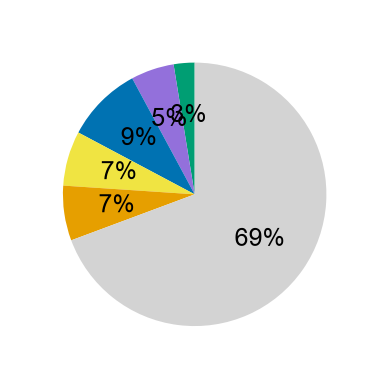

In [3]:
tissue_colors_with_unsampled = tissue_colors.copy()
tissue_colors_with_unsampled["Unsampled"] = "lightgrey"
target_names_with_unsampled = target_names + ["Unsampled"]
dominant_fate_proportions = np.sum(
    fate_matrix_with_unsampled_Stitch[:, :], axis=0
) / np.sum(fate_matrix_with_unsampled_Stitch[:, :])
print(dominant_fate_proportions)
# Plot 2: Pie chart of dominant fates
fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout="constrained")
colors = [
    tissue_colors_with_unsampled[tissue] for tissue in target_names_with_unsampled
]
ax.pie(
    dominant_fate_proportions,
    autopct="%1.0f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.6,
)
plt.savefig(figure_path + "dominant_fate_pie_chart_unsampled.pdf")

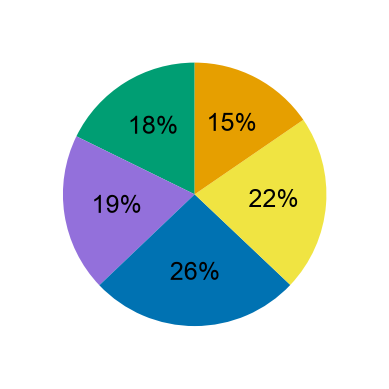

In [4]:
# select the most dominant fate for each cell and plot statistics in pie chart. Meaning relative transition probabilities for blood cells in general
dominant_fate_proportions = np.sum(fate_matrix_Stitch, axis=0) / np.sum(
    fate_matrix_Stitch
)

# Plot 2: Pie chart of dominant fates
fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout="constrained")
colors = [tissue_colors[tissue] for tissue in target_names]
ax.pie(
    dominant_fate_proportions,
    autopct="%1.0f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.6,
)
plt.savefig(figure_path + "dominant_fate_pie_chart.pdf")

### Analysis only on markers (corresponding genes) considered by Wong et al.

In [5]:
columns_order = [
    "CCR2",
    "CCR4",
    "CCR5",
    "CCR6",
    "CCR7",
    "CCR9",
    "CCR10",
    "CD29",
    "CD31",
    "CD103",
    "CD62L",
    "CD49a",
    "CD49d",
    "CLA",
    "CXCR3",
    "CXCR4",
    "CXCR5",
    "CXCR6",
    "CX3CR1",
    "IntegrinB7",
]
columns_order_diff = [
    "CD25",
    "CD27",
    "CD45RA",
    "CD45RO",
    "CD69",
    "CD95",
    "CD127",
    "CD161",
    "ICOS",
    "PD-1",
]

marker_to_genename_dict = {
    "CCR2": "CCR2",
    "CCR4": "CCR4",
    "CCR5": "CCR5",
    "CCR6": "CCR6",
    "CCR7": "CCR7",
    "CCR9": "CCR9",
    "CCR10": "CCR10",
    "CD29": "ITGB1",
    "CD31": "PECAM1",
    "CD103": "ITGAE",
    "CD62L": "SELL",
    "CD49a": "ITGA1",
    "CD49d": "ITGA4",
    "CLA": "SELPLG",
    "CXCR3": "CXCR3",
    "CXCR4": "CXCR4",
    "CXCR5": "CXCR5",
    "CXCR6": "CXCR6",
    "CX3CR1": "CX3CR1",
    "IntegrinB7": "ITGB7",
    "CD25": "IL2RA",
    "CD27": "CD27",
    "CD45RA": "PTPRC",
    "CD45RO": "PTPRC",
    "CD69": "CD69",
    "CD95": "FAS",
    "CD127": "IL7R",
    "CD161": "KLRB1",
    "ICOS": "ICOS",
    "PD-1": "PDCD1",
}
# add new .var column and only set genes in this list to True, all others to False
# use dict to get corresponding gene names for the markers
adata_OT.var["in_Wong"] = False
adata_OT.var.loc[
    [marker_to_genename_dict[marker] for marker in columns_order + columns_order_diff],
    "in_Wong",
] = True
# only keep genes that are in the Wong list
adata_OT = adata_OT[:, adata_OT.var["in_Wong"]].copy()
# delete duplicates
adata_OT = adata_OT[:, ~adata_OT.var_names.duplicated()].copy()
# reorder columns in adata_OT.var according to columns_order + columns_order_diff
new_order = [
    marker_to_genename_dict[marker] for marker in columns_order + columns_order_diff
]
adata_OT = adata_OT[:, new_order].copy()
# delete duplicates again
# adata_OT = adata_OT[:, ~adata_OT.var_names.duplicated()].copy()

/tmp/ipykernel_138323/2828300153.py:83: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata_OT = adata_OT[:, new_order].copy()


### Trafficking signatures only using markers measured by Wong et al.

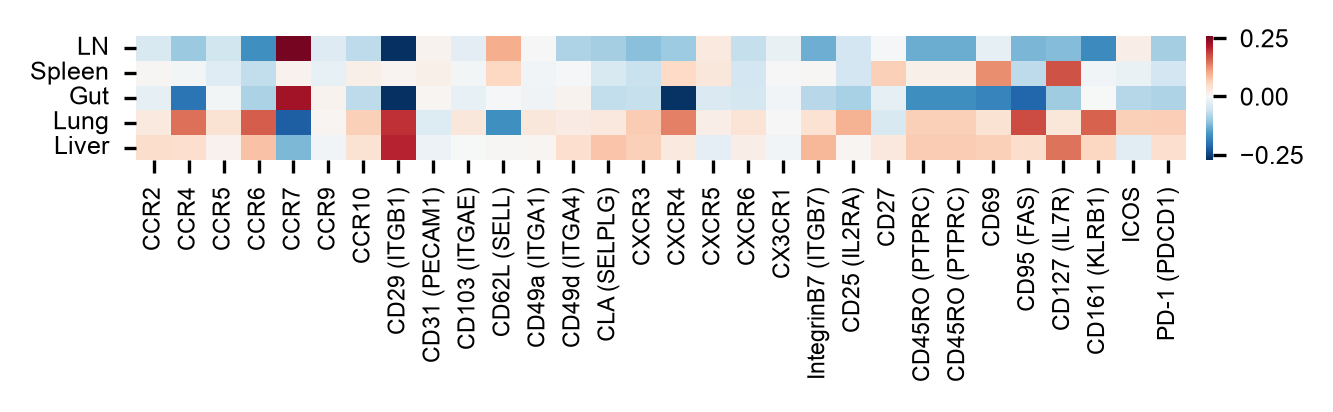

In [ ]:
import seaborn as sns

# import spearmanr from scipy.stats
from scipy.stats import spearmanr

# Compute pairwise correlations between each fate and each marker
correlation_results = {}
for fate_col in range(
    fate_matrix_Stitch.shape[1]
):  # Transpose to iterate over columns (fates)
    for marker in adata_OT.var_names:
        # correlate using spearman correlation
        # if marker is in duplicate, skip it
        if marker != "PTPRC":
            corr, _ = spearmanr(
                fate_matrix_Stitch[:, fate_col],
                np.asarray(adata_OT[mask_source, marker].X.todense()).flatten(),
            )
        else:
            corr, _ = spearmanr(
                fate_matrix_Stitch[:, fate_col],
                np.asarray(adata_OT[mask_source, marker].X.todense()[:, 0]).flatten(),
            )
        # if resultsi s nan, set to 0
        if np.isnan(corr):
            corr = 0
        correlation_results[f"{fate_col}_vs_{marker}"] = corr

corr_matrix_df = pd.DataFrame(
    index=target_names, columns=adata_OT.var_names, dtype=float
)
for fate_col in range(fate_matrix_Stitch.shape[1]):
    for marker in adata_OT.var_names:
        corr_matrix_df.loc[target_names[fate_col], marker] = correlation_results[
            f"{fate_col}_vs_{marker}"
        ]

# reorder corr_matrix_df rows to be LN, Spleen, Gut, Lung, Liver
corr_matrix_df = corr_matrix_df.reindex(["LN", "Spleen", "Gut", "Lung", "Liver"])
# Plot 1: Heatmap of correlations
# cbar ticks should be at -0.5, -0.25, 0, 0.25, 0.5
fig, ax = plt.subplots(figsize=(11, 3.2, "cm"), layout="constrained")
cbar = sns.heatmap(
    corr_matrix_df,
    annot=False,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={"shrink": 1, "ticks": [-0.5, -0.25, 0, 0.25, 0.5], "pad": 0.02},
    ax=ax,
    xticklabels=True,
)

# ax.set_title('Correlation between Fate Probabilities and Marker Expression')
ax.set_xlabel("")
# for markers that have not the same gene name, add the gene name in brackets to the marker name
genename_to_marker_dict = {v: k for k, v in marker_to_genename_dict.items()}
ax.set_xticklabels(
    [
        f"{genename_to_marker_dict[gene_name]} ({gene_name})"
        if genename_to_marker_dict[gene_name] != gene_name
        else gene_name
        for gene_name in corr_matrix_df.columns
    ],
    rotation=90,
    fontsize=5.5,
)  
ax.set_yticklabels(labels=ax.get_yticklabels(), rotation=0)
# ax.set_xticklabels(labels=ax.get_xticklabels(), rotation=90)
ax.set_ylabel("")
plt.savefig(figure_path + "correlation_heatmap.pdf")
plt.show()

### Look for homing niches in UMAP projection

In [7]:
import umap

# Do a Umap of colon cells
for tissue in target_names:
    # extract colon cells from adata_OT
    colon_cells = data_target[selected_target_mask_Joint][
        target_locations[selected_target_mask_Joint] == tissue
    ]
    umap_colon = umap.UMAP(
        n_neighbors=30, min_dist=0.3, spread=1, random_state=42
    ).fit_transform(colon_cells)
    # plot umap embedding of colon cells
    fig, ax = plt.subplots(figsize=(2.2, 3.4, "cm"), layout="constrained")
    ax.scatter(
        umap_colon[:, 0],
        umap_colon[:, 1],
        c="darkgray",
        s=1.5,
        alpha=0.6,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # dont show the axes
    ax.set_xticks([])
    ax.set_yticks([])
    # now compute the average coordinates of all blood cells that have a fate probability greater than 0.35 for colon and plot this point on the umap
    blood_cells_fate_prob = fate_matrix_Joint[:, target_names.index(tissue)]
    # compute the average coordinates of these blood cells by multiplying the coupling matrix with the colon cells coordinates
    blood_cells_high_fate_coupling = coupling_matrix_Joint[
        blood_cells_fate_prob > 1 / 3, :
    ][:, target_locations[selected_target_mask_Joint] == tissue]

    # Normalize the selected weights so they sum to 1 for each blood cell.
    # Otherwise the weighted sum is a scaled affine combination and can fall outside the convex hull of the tissue coordinates.
    row_sums = blood_cells_high_fate_coupling.sum(axis=1, keepdims=True)
    normalized_weights = np.divide(
        blood_cells_high_fate_coupling,
        row_sums,
        out=np.zeros_like(blood_cells_high_fate_coupling),
        where=row_sums > 0,
    )

    blood_cells_high_fate_projected = normalized_weights @ umap_colon
    print(
        "blood_cells_high_fate_projected shape:", blood_cells_high_fate_projected.shape
    )

    ax.scatter(
        blood_cells_high_fate_projected[:, 0],
        blood_cells_high_fate_projected[:, 1],
        c=tissue_colors[tissue],
        s=3,
        label="Blood cells projected to " + tissue,
        alpha=0.95,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # ax.legend(fontsize=6)
    # dont show the axes
    ax.set_xticks([])
    ax.set_yticks([])
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.gca().spines["bottom"].set_visible(False)
    plt.gca().spines["left"].set_visible(False)
    plt.savefig(figure_path + "umap_" + tissue + "_with_blood_projection_.pdf", dpi=600)
    plt.close()

    # color by CCR7 expression
    # fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout='constrained')
    # gene_expressions = adata_OT.X[:, adata.var_names.get_loc('CCR7')].todense()[adata_OT.obs['Organ'] != source_name][selected_target_mask][target_locations[selected_target_mask] == tissue]
    # gene_expressions =np.asarray(gene_expressions).flatten()
    # ax.scatter(umap_colon[:, 0], umap_colon[:, 1], c=gene_expressions, cmap='viridis', s=5, alpha=0.5)
    # ax.set_title('UMAP Embedding of ' + tissue + ' Cells colored by CCR7 expression')
    # ax.set_xticks([])
    # ax.set_yticks([])
    # plt.savefig(figure_path + 'umap_' + tissue + '_colored_by_CCR7_expression_.pdf', dpi=300)
    # plt.close()

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (1835, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (467, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (4607, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (2231, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (3879, 2)
